In [3]:
from pathlib import Path
import os
import sys

# Find the main project folder
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Add project folder to Python's search path
sys.path.insert(0, str(PROJECT_ROOT))

# Set working directory
os.chdir(PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)
print("src folder exists:", (PROJECT_ROOT / "src").exists())

Project root: c:\Users\menna\Documents\GitHub\Network-Intrusion-Detection
src folder exists: True


In [4]:
from src.data import load_train, load_test

train = load_train()
test = load_test()

print("Training:", train.shape)
print("Testing:", test.shape)

Training: (175341, 45)
Testing: (82332, 45)


In [5]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Load project datasets
from src.data import load_train, load_test

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load datasets
train = load_train()
test = load_test()

print("Datasets loaded successfully!")
print("Training shape:", train.shape)
print("Testing shape:", test.shape)

Datasets loaded successfully!
Training shape: (175341, 45)
Testing shape: (82332, 45)


In [6]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [7]:
train.tail()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
175336,175337,0.000009,udp,dns,INT,2,0,114,0,111111.107200,...,13,24,0,0,0,24,24,0,Generic,1
175337,175338,0.505762,tcp,-,FIN,10,8,620,354,33.612649,...,1,2,0,0,0,1,1,0,Shellcode,1
175338,175339,0.000009,udp,dns,INT,2,0,114,0,111111.107200,...,3,13,0,0,0,3,12,0,Generic,1
175339,175340,0.000009,udp,dns,INT,2,0,114,0,111111.107200,...,14,30,0,0,0,30,30,0,Generic,1
175340,175341,0.000009,udp,dns,INT,2,0,114,0,111111.107200,...,16,30,0,0,0,30,30,0,Generic,1


In [8]:
print("Number of columns:", len(train.columns))

print("\nColumn names:")
for col in train.columns:
    print(col)

Number of columns: 45

Column names:
id
dur
proto
service
state
spkts
dpkts
sbytes
dbytes
rate
sttl
dttl
sload
dload
sloss
dloss
sinpkt
dinpkt
sjit
djit
swin
stcpb
dtcpb
dwin
tcprtt
synack
ackdat
smean
dmean
trans_depth
response_body_len
ct_srv_src
ct_state_ttl
ct_dst_ltm
ct_src_dport_ltm
ct_dst_sport_ltm
ct_dst_src_ltm
is_ftp_login
ct_ftp_cmd
ct_flw_http_mthd
ct_src_ltm
ct_srv_dst
is_sm_ips_ports
attack_cat
label


In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  si

In [10]:
numerical_cols = train.select_dtypes(include=np.number).columns.tolist()

categorical_cols = train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

print("\nNumber of numerical columns:", len(numerical_cols))
print("Number of categorical columns:", len(categorical_cols))

Numerical columns:
['id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'label']

Categorical columns:
['proto', 'service', 'state', 'attack_cat']

Number of numerical columns: 41
Number of categorical columns: 4


In [11]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,175341.0,8.767100e+04,5.061673e+04,1.0,43836.000000,87671.000000,1.315060e+05,1.753410e+05
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786140,3225.806520,1.250000e+05,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000000,254.000000,2.540000e+02,2.550000e+02
dttl,175341.0,7.960957e+01,1.105069e+02,0.0,0.000000,29.000000,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338870,879674.750000,8.888889e+07,5.988000e+09


In [12]:
train.describe(include="object").T

,count,unique,top,freq
proto,175341,133,tcp,79946
service,175341,13,-,94168
state,175341,9,INT,82275
attack_cat,175341,10,Normal,56000


In [13]:
missing_values = train.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(train)) * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage
id,0,0.0
dwin,0,0.0
synack,0,0.0
ackdat,0,0.0
smean,0,0.0
dmean,0,0.0
trans_depth,0,0.0
response_body_len,0,0.0
ct_srv_src,0,0.0
ct_state_ttl,0,0.0


In [14]:
print("Number of duplicated rows:", train.duplicated().sum())

Number of duplicated rows: 0


In [15]:
for col in categorical_cols:
    print(f"\nColumn: {col}")
    print("Unique values:", train[col].nunique())
    print(train[col].value_counts().head(10))


Column: proto
Unique values: 133
proto
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
sctp       1150
any         300
gre         225
sun-nd      201
ipv6        201
Name: count, dtype: int64

Column: service
Unique values: 13
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
Name: count, dtype: int64

Column: state
Unique values: 9
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64

Column: attack_cat
Unique values: 10
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [16]:
print("Label counts:")
print(train["label"].value_counts())

print("\nLabel percentages:")
print(train["label"].value_counts(normalize=True) * 100)

Label counts:
label
1    119341
0     56000
Name: count, dtype: int64

Label percentages:
label
1    68.062233
0    31.937767
Name: proportion, dtype: float64


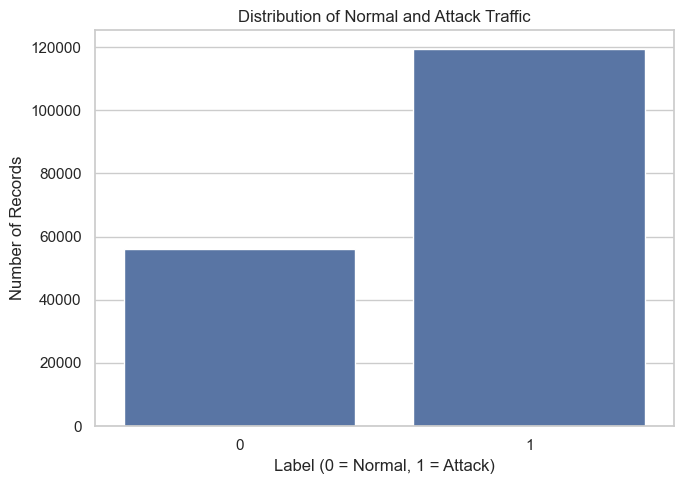

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(data=train, x="label")

plt.title("Distribution of Normal and Attack Traffic")
plt.xlabel("Label (0 = Normal, 1 = Attack)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [18]:
print(train["attack_cat"].value_counts())

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


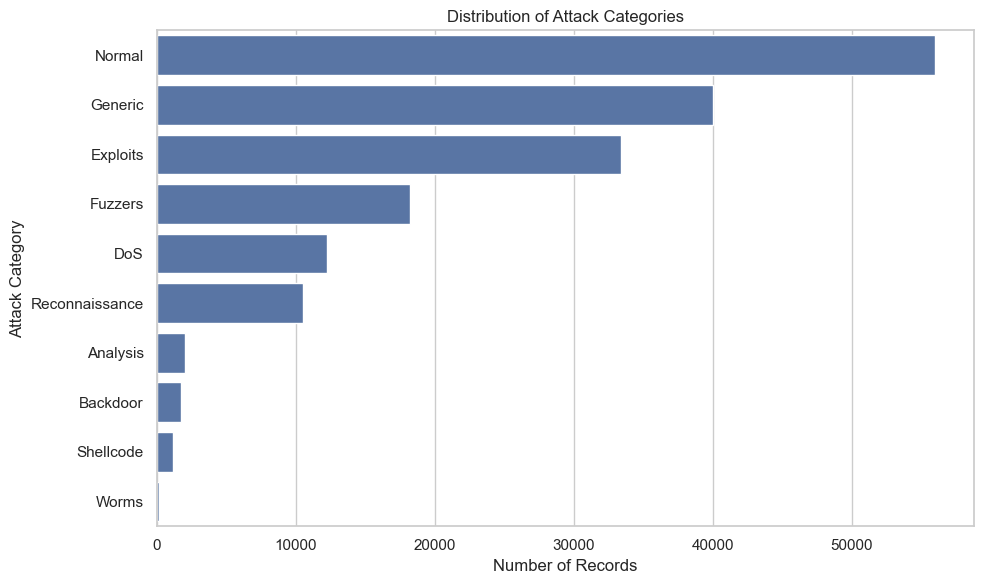

In [19]:
plt.figure(figsize=(10, 6))

attack_counts = train["attack_cat"].value_counts()

sns.barplot(
    x=attack_counts.values,
    y=attack_counts.index
)

plt.title("Distribution of Attack Categories")
plt.xlabel("Number of Records")
plt.ylabel("Attack Category")

plt.tight_layout()
plt.show()

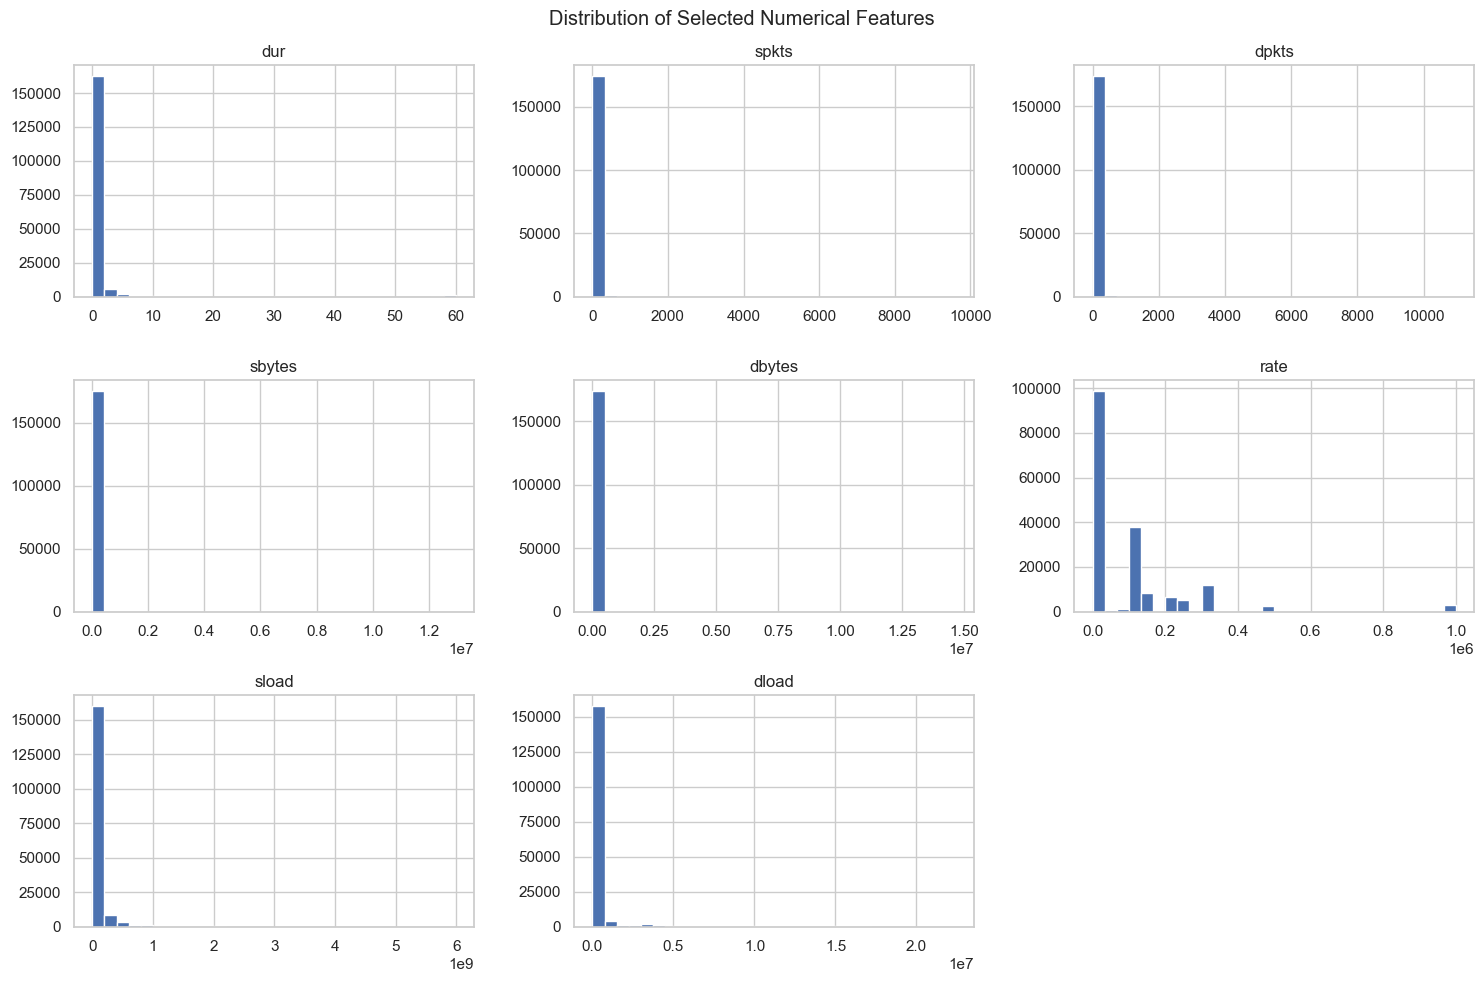

In [20]:
selected_features = [
    "dur",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate",
    "sload",
    "dload"
]

train[selected_features].hist(
    bins=30,
    figsize=(15, 10)
)

plt.suptitle("Distribution of Selected Numerical Features")
plt.tight_layout()
plt.show()

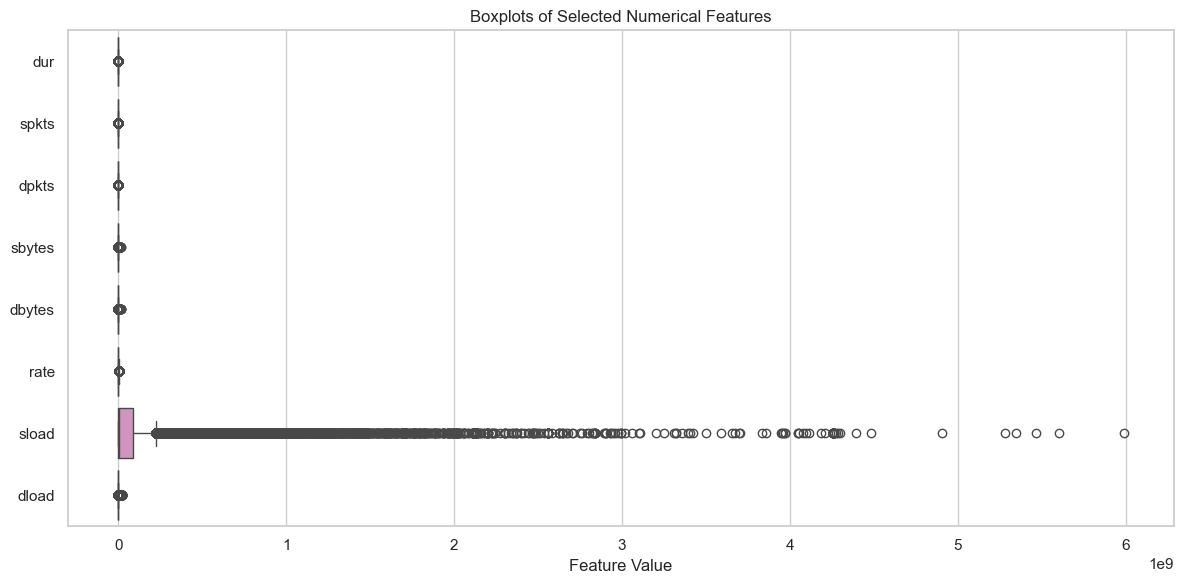

In [21]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=train[selected_features], orient="h")

plt.title("Boxplots of Selected Numerical Features")
plt.xlabel("Feature Value")

plt.tight_layout()
plt.show()

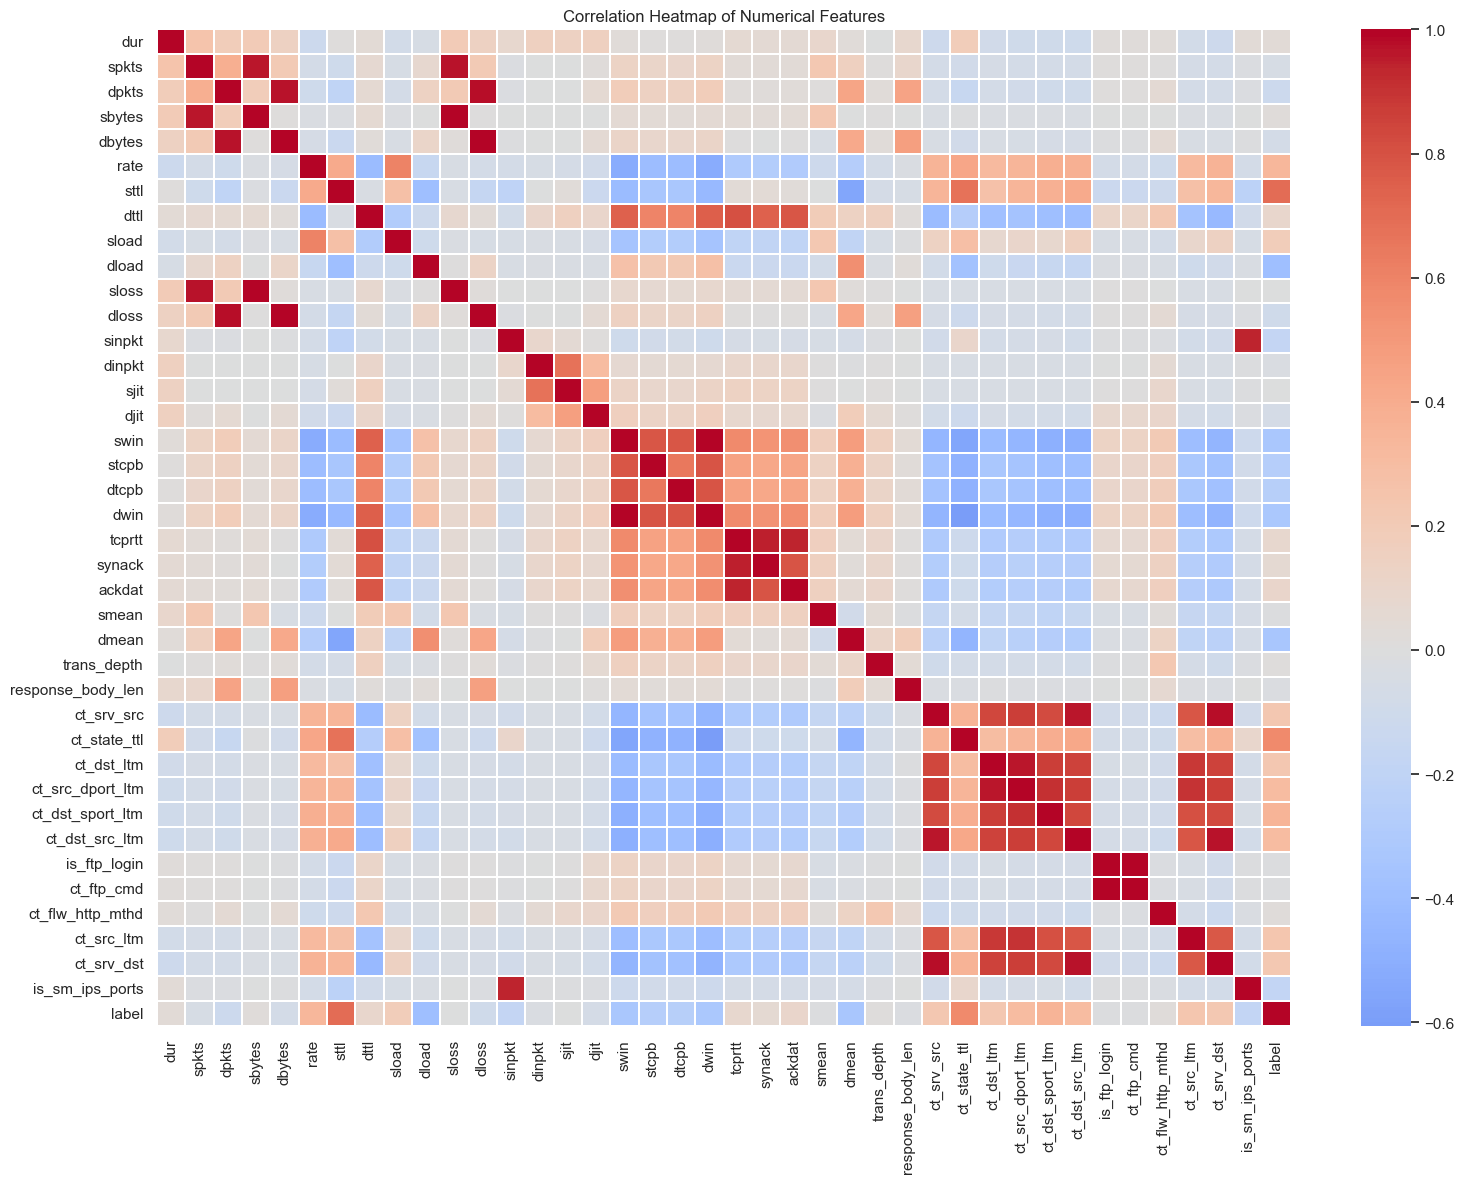

In [28]:
# Exclude identifier from correlation analysis
numeric_data = train.select_dtypes(include=np.number).drop(
    columns=["id"],
    errors="ignore"
)

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [23]:
correlation_matrix = train.select_dtypes(
    include=np.number
).corr()

correlation_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
).head(15)

,Feature 1,Feature 2,Correlation,Absolute Correlation
799,is_ftp_login,ct_ftp_cmd,1.000000,1.000000
196,dbytes,dloss,0.996504,0.996504
160,sbytes,sloss,0.996109,0.996109
546,swin,dwin,0.990140,0.990140
751,ct_srv_src,ct_srv_dst,0.980323,0.980323
125,dpkts,dloss,0.978636,0.978636
796,ct_dst_src_ltm,ct_srv_dst,0.972370,0.972370
118,dpkts,dbytes,0.971907,0.971907
87,spkts,sloss,0.971069,0.971069
746,ct_srv_src,ct_dst_src_ltm,0.967138,0.967138


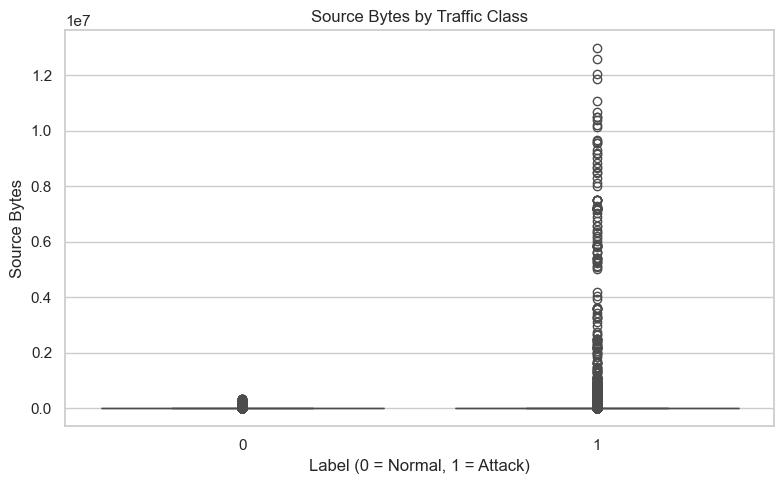

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train,
    x="label",
    y="sbytes"
)

plt.title("Source Bytes by Traffic Class")
plt.xlabel("Label (0 = Normal, 1 = Attack)")
plt.ylabel("Source Bytes")

plt.tight_layout()
plt.show()

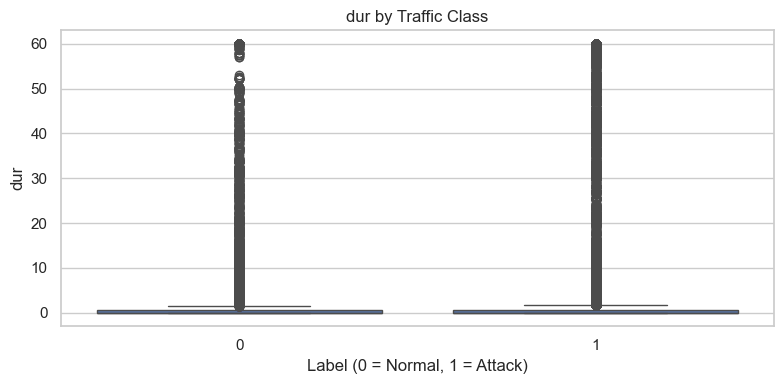

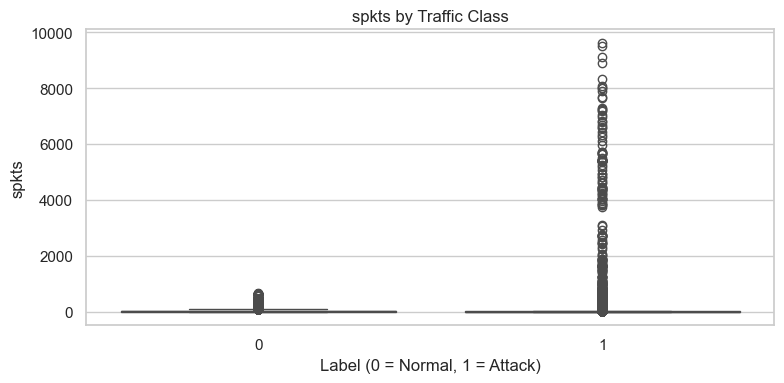

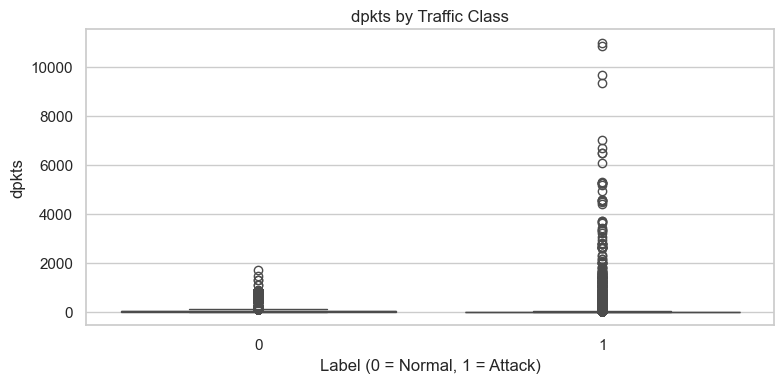

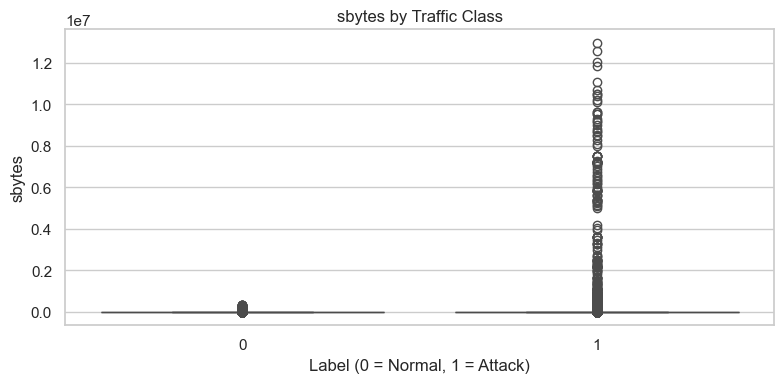

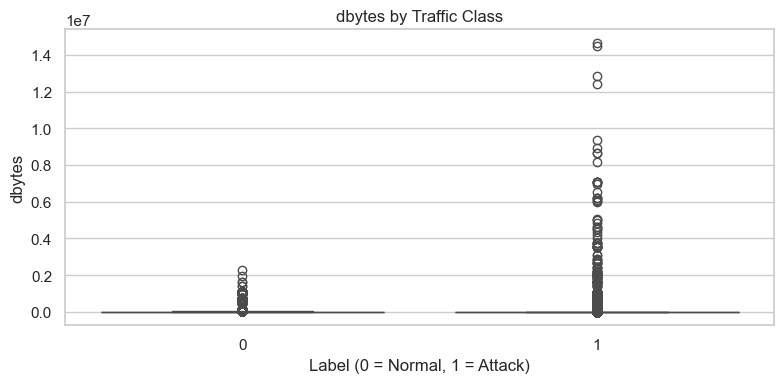

In [25]:
features_to_compare = ["dur", "spkts", "dpkts", "sbytes", "dbytes"]

for feature in features_to_compare:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=train,
        x="label",
        y=feature
    )

    plt.title(f"{feature} by Traffic Class")
    plt.xlabel("Label (0 = Normal, 1 = Attack)")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

In [26]:
print("Training label distribution:")
print(train["label"].value_counts(normalize=True) * 100)

print("\nTesting label distribution:")
print(test["label"].value_counts(normalize=True) * 100)

Training label distribution:
label
1    68.062233
0    31.937767
Name: proportion, dtype: float64

Testing label distribution:
label
1    55.060001
0    44.939999
Name: proportion, dtype: float64


In [27]:
print("========== EDA SUMMARY ==========")

print("\nTraining dataset:")
print("Rows:", train.shape[0])
print("Columns:", train.shape[1])

print("\nTesting dataset:")
print("Rows:", test.shape[0])
print("Columns:", test.shape[1])

print("\nMissing values:", train.isnull().sum().sum())

print("Duplicated rows:", train.duplicated().sum())

print("\nNormal and attack records:")
print(train["label"].value_counts())

print("\nAttack categories:")
print(train["attack_cat"].value_counts())

print("\nEDA completed!")

========== EDA SUMMARY ==========

Training dataset:
Rows: 175341
Columns: 45

Testing dataset:
Rows: 82332
Columns: 45

Missing values: 0
Duplicated rows: 0

Normal and attack records:
label
1    119341
0     56000
Name: count, dtype: int64

Attack categories:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

EDA completed!


In [29]:
print("Label counts:")
print(train["label"].value_counts())

print("\nLabel percentages:")
print(train["label"].value_counts(normalize=True) * 100)

Label counts:
label
1    119341
0     56000
Name: count, dtype: int64

Label percentages:
label
1    68.062233
0    31.937767
Name: proportion, dtype: float64
